In [1]:
from bbresults import BackboneScenarioAnalysis
from bbresults import BackboneResult
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle as pickle
import plotly.express as px

In [ ]:
###Figures 2 and 3

In [ ]:
#Load results from your path
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")

In [ ]:
###Figure 2: Electricity and hydrogen generation capacities installed
#retrieve capacities 
df=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):
    p_gnu_io=r.param_as_df("p_gnu_io")
    unitUnittype=r.set_as_df("unitUnittype")    
    p_gnu_io=p_gnu_io.query("grid == 'elec'")
    #p_gnu_io=p_gnu_io[p_gnu_io['input_output']=='output']
    p_gnu_io=p_gnu_io[p_gnu_io["unit"].apply(lambda x: 1 if any(i in x for i in ["ev","Charge"]) else 0)==0]

    p_gnu_io=p_gnu_io[p_gnu_io["param_gnu"]=="capacity"]
    p_gnu_io=p_gnu_io.merge(unitUnittype,on="unit")
    p_gnu_io["scen"]=str(s)
    df = pd.concat([df,p_gnu_io])

In [ ]:
#renaming
df["scen"] = df["scen"].str.replace(r"2019.*", "", regex=True)
df = df.drop_duplicates(subset=["scen", "value"], keep="first")
df["scen"][df["scen"]=="Base "]="H2Price+PVCost-"
df["scen"][df["scen"]=="BasePV- "]="H2Price+PVCost+"
df["scen"][df["scen"]=="H2Price- "]="H2Price-PVCost-"
df["scen"][df["scen"]=="H2Price-PV- "]="H2Price-PVCost+"
#nodes=["AT elec","CZ elec","SE elec","IE elec","BT elec","PT elec","IT elec","BK elec"]
nodes=["DK elec", "FR elec", "ES elec"]
df=df[df['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==1]
df["unit"]=df["unit"].map(lambda x: str(x)[3:])
df["unittype"][df["unit"].apply(lambda x: 1 if any(i in x for i in ["Wind Onshore New 1"]) else 0)==1]="Wind Onshore High FLH"
df["unittype"][df["unit"].apply(lambda x: 1 if any(i in x for i in ["Wind Onshore New 2"]) else 0)==1]="Wind Onshore High MV"
df["unittype"][df["unit"].apply(lambda x: 1 if any(i in x for i in ["Solar"]) else 0)==1]="Solar"
df["unittype"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["Solar CSP"]) else 0)==1]="Solar"
df["unittype"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["ror"]) else 0)==1]="Run of River"
df["unittype"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["biofuel"]) else 0)==1]="Biofuel"
df["unittype"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["Others renewable"]) else 0)==1]="Waste"
df["unittype"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["H2 turbine"]) else 0)==1]="H2 Turbine"

df=df[df["unittype"]!="dsr"]
df=df.groupby(["node","unittype","scen"]).sum().reset_index()
df["sorter"]="a"
df["sorter"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["electrolyser"]) else 0)==1]="e"
df["sorter"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["Biofuel","Waste","H2 Turbine","Nuclear"]) else 0)==1]="d"
df["sorter"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["PHS","Hydro","Run of River"]) else 0)==1]="c"
df["sorter"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["Batteries","Offshore"]) else 0)==1]="b"
df["sorter"][df["unittype"].apply(lambda x: 1 if any(i in x for i in ["Solar","Onshore"]) else 0)==1]="a"
df=df.sort_values(["sorter","unittype"])

df=df.rename(columns={"unittype":"Technology"})
df["GW"]=df["value"]/1000

C:\Users\silke\AppData\Local\Temp\ipykernel_4392\2358993015.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["scen"][df["scen"]=="Base "]="H2Price+PVCost-"
C:\Users\silke\AppData\Local\Temp\ipykernel_4392\2358993015.py:4: FutureWarning

In [ ]:
#color dictionary
color_dict={'Solar CSP':'lemonchiffon','Solar PV large':'gold', 'Solar CSP New':'lemonchiffon','Solar PV large New':'yellow','Solar':'gold',
             'Solar PV rooftop New':'yellow','Batteries Discharge New': 'cyan', 'Batteries Charge New': 'cyan',  'Wind Onshore New':'lightgrey',
             'ROR':'lightblue', 'Run of River':'dodgerblue','Wind Onshore': 'lightgrey', 'Wind Offshore New':'dimgrey',
             'Wind Onshore High FLH':'darkgrey', 'Wind Onshore High MV':'grey',
             'Solar PV rooftop':'yellow','Batteries Discharge New': 'cyan', 'Batteries Charge New': 'cyan',
             'Hydro Discharge':'mediumblue', 'PHS Charge':'deepskyblue', 'PHS Discharge':'deepskyblue', 'Pumped Hydro Storage':'deepskyblue', 
             'Pumped Hydro Discharge':'deepskyblue', 'HVAC_elec':'hotpink', 'electric HVAC':'hotpink','HVAC_fuel':'darkmagenta','ev':'violet',
             'Batteries New Discharge': 'cyan', 'Batteries New Charge': 'cyan', 'ror': 'dodgerblue',
             'Batteries Discharge': 'cyan', 'Batteries Charge': 'cyan', 'ROR': 'dodgerblue', 'supplier':'hotpink',
             'Batteries Res Discharge': 'darkcyan', 'electric HVAC':'hotpink', 'fuel HVAC':'darkmagenta',
             'Batteries Res Charge': 'darkcyan', 'aggregator': 'orange','EV':'orange',
             'Wind Offshore':'darkslategrey', 'electrolyser': 'darkcyan','H2 electrolyser': 'darkcyan','Other non-thermal renewables':'lightblue',
             'Others renewable':'darkgreen', 'Thermal renewables':'darkseagreen','Waste':'darkgreen','Other thermal renewables':'darkgreen','Nuclear':'purple', 'Nuclear New':'purple',
             'Others non-renewable':'peachpuff', 'Others renewable New':'darkgreen', 'Oil':'orange', 'Biofuel New':'limegreen',
             'Gas':'peru', 'Synthetic Gas':'peru', 'Biofuel':'limegreen', 'Hard Coal':'black', 'Lignite':'saddlebrown',  'H2 turbine': 'cadetblue', 'H2 Turbine': 'cadetblue',
             'residential.A2WHP_DHW': 'green', 'residential.A2WHP_radiators': 'green', 'residential.ideal_cooling': 'green',
             'ev': 'orange', 'Load':'blue','DSR':'red','dsr':'red','biofuel':'limegreen','Demand-Side Response':'red'}

In [ ]:
#bar-plot
fig = px.bar(df, x='scen', y='GW',facet_col="node",color="Technology",color_discrete_map=color_dict,facet_col_spacing=0.1)
fig.update_layout(barmode='stack',plot_bgcolor='rgba(0,0,0,0)',legend=dict(
            #y=0.5,
             traceorder="reversed",font_size=12
            ),width=700,
                height=490,font_size=12,font_color="black")
fig.update_yaxes(linecolor="black",title_standoff = 0.5,ticks='outside')
fig.update_xaxes(linecolor="black",title="")
fig.update_xaxes(tickangle=270)
fig.update_yaxes(showticklabels=True, matches=None)
for annotation in fig.layout.annotations:
    annotation.text = annotation.text.replace("node=", "")
for annotation in fig.layout.annotations:
    clean_text = annotation.text.replace("elec", "")
    annotation.text = f"<b>{clean_text}</b>"
fig.show()


In [ ]:
#Figure 3: Electricity price distribution
df=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):
    r_balanceMarginal = r.r_balanceMarginal().rename(columns={"Val": "Price"})
    r_balanceMarginal = r_balanceMarginal[r_balanceMarginal["grid"].apply(lambda x: 1 if any(i in x for i in ["elec"]) else 0) == 1]
    r_balanceMarginal["Price"] = r_balanceMarginal["Price"].fillna(0)
    r_balanceMarginal["Price"]= r_balanceMarginal["Price"]*-1
    r_balanceMarginal=r_balanceMarginal[["node","Price"]]
    r_balanceMarginal["scen"]=s
    df = pd.concat([df,r_balanceMarginal])

In [ ]:
#rearranging and colors
df_DE=df[df["node"]=="DE elec"]
df_ES=df[df["node"]=="ES elec"]
df_PL=df[df["node"]=="PL elec"]

df["invest_scen"] = df["scen"].str.replace(r"2019.*", "", regex=True)
df["dispatch_scen"]= df["scen"].str.extract(r"2019 (.*)")
df["invest_scen"][df["invest_scen"]=="Base "]="H2Price+PVCost-"
df["invest_scen"][df["invest_scen"]=="BasePV- "]="H2Price+PVCost+"
df["invest_scen"][df["invest_scen"]=="H2Price- "]="H2Price-PVCost-"
df["invest_scen"][df["invest_scen"]=="H2Price-PV- "]="H2Price-PVCost+"

df_3nodes=df[df["node"].apply(lambda x: 1 if any(i in x for i in ["DK elec","FR elec","ES elec"]) else 0)==1]
df_3nodes["node"]=df_3nodes["node"].map(lambda x: str(x)[:2])

palette3 = {
    "FR": "mediumorchid",  
     "DK": "grey",  
        "ES": "gold",  
}

In [8]:
#add demand response price as max price
res1=res.bb_results[0]
p_gnu_io=res1.param_as_df("p_gnu_io")
unitUnittype=res1.set_as_df("unitUnittype")
p_gnu_io=p_gnu_io.merge(unitUnittype,on="unit")
p_gnu_io["vomCosts"]=p_gnu_io[p_gnu_io['param_gnu']=='vomCosts']["value"]
dsr=p_gnu_io[p_gnu_io["unittype"]=="dsr"]
dsr=dsr[["node","vomCosts"]]
dsr=dsr.rename(columns={"vomCosts": "maxprice"})
maxprice = dsr['maxprice'].max()
df_3nodes.loc[
    (df_3nodes["Price"] > maxprice) 
    #& (df_3nodes["Price"] < 3999)
    ,
    "Price"
] = maxprice

<Figure size 300x500 with 0 Axes>

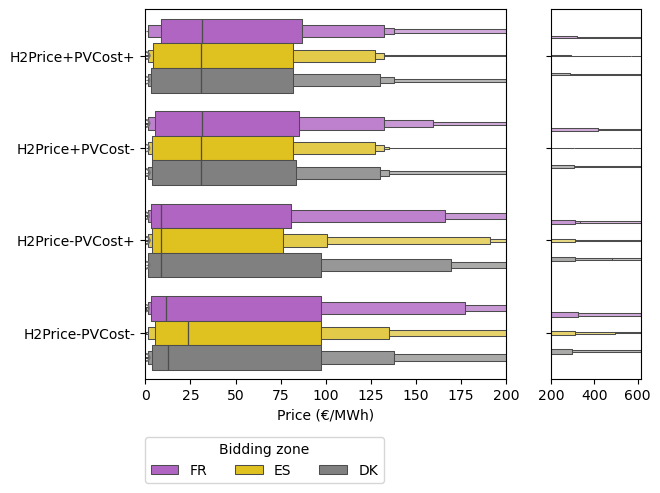

In [ ]:
#letter-value-plot
plt.figure(figsize=(3, 5))
f, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, sharey=True, gridspec_kw={'width_ratios': [4, 1]})
cat_order = pd.Categorical(df_3nodes['invest_scen']).categories.tolist()
n = len(cat_order)
nodes = df_3nodes['node'].unique()
# Left boxplot
sns.boxenplot(
    data=df_3nodes,
    x="Price",
    y="invest_scen",
    hue="node",
    ax=ax1,
    width=0.8,
    order=cat_order,
    palette=palette3
)

sns.boxenplot(
    data=df_3nodes,
    x="Price",
    y="invest_scen",
    hue="node",
    ax=ax2,
    width=0.6,
    order=cat_order,
    palette=palette3,legend=None
)

ax1.set_xlim(0, 200)
ax2.set_xlim(200, 617)
ax2.set_xticks(range(200,617,200))
ax2.set_xlabel('')
yticks_positions = list(range(n))
ax1.set_yticks(yticks_positions)
ax1.set_yticklabels(cat_order, rotation=0)
ax1.set_ylabel("")
ax1.set_xlabel("Price (€/MWh)")

sns.move_legend(
    ax1,
    "lower center",
    bbox_to_anchor=(0.33, -0.3),  
    ncol=3,                       
    title="Bidding zone",
           
)
plt.show()
